# EDA básico e inspección de calidad de Feina Activa

## 1. Configuración y librerías. 

Importamos las librerías necesarias para hacer la petición HTTP, leer el XML, manipular datos en tablas con `pandas`/`numpy`, generar gráficos sencillos y manejar rutas de forma portable con `pathlib`.

In [27]:
# Librerías y configuración
import json
from datetime import datetime, timezone
from pathlib import Path
import requests
import xml.etree.ElementTree as ET
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 1000)

%matplotlib inline
sns.set_theme(style="whitegrid")

## 2. Acceso y descarga de la muestra raw.

Conectamos con el endpoint de Feina Activa, comprobamos el estado de la respuesta y guardamos el XML sin modificar en `data/raw/feina_activa/`, junto con un `metadata_extraccion.json` en esa misma carpeta para registrar fecha, tamaño y respuesta HTTP.

In [28]:
# Acceso y descarga de muestra raw
URL_FEINA_ACTIVA = "https://feinaactiva.gencat.cat/api/offers/offers-xml"

RAW_DIR = Path("../data/raw/feina_activa")
RAW_DIR.mkdir(parents=True, exist_ok=True)

RAW_XML_PATH = RAW_DIR / "offers_feina_activa_raw.xml"
META_PATH = RAW_DIR / "metadata_extraccion.json"

headers = {
    "User-Agent": "Proyecto-Grupal-Evolve-Master/1.0 (uso academico)"
}

try:
    response = requests.get(URL_FEINA_ACTIVA, headers=headers, timeout=30)
    print(f"Código HTTP: {response.status_code}")
    print(f"Content-Type: {response.headers.get('Content-Type')}")
    print(f"Tamaño recibido: {len(response.content) / 1024:.2f} KB")

    response.raise_for_status()

    # Guardamos el contenido exacto sin modificar (capa raw)
    RAW_XML_PATH.write_bytes(response.content)

    # Guardamos metadatos de trazabilidad de la descarga
    metadata = {
        "fuente": "Feina Activa (Generalitat de Catalunya)",
        "url": URL_FEINA_ACTIVA,
        "fecha_extraccion_utc": datetime.now(timezone.utc).isoformat(),
        "status_code": response.status_code,
        "content_type": response.headers.get("Content-Type"),
        "tamano_bytes": len(response.content),
        "archivo_guardado": str(RAW_XML_PATH)
    }
    META_PATH.write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
    print(f"\nArchivo guardado correctamente en: {RAW_XML_PATH}")

except requests.exceptions.RequestException as e:
    print(f"Error al conectar o descargar desde Feina Activa: {e}")

Código HTTP: 200
Content-Type: application/xml;charset=UTF-8
Tamaño recibido: 7331.05 KB

Archivo guardado correctamente en: ..\data\raw\feina_activa\offers_feina_activa_raw.xml


La descarga se ha completado con éxito (`Código HTTP: 200`, `Content-Type: application/xml;charset=UTF-8` y un tamaño de `7309.23 KB`), conservando la muestra XML intacta en `data/raw/feina_activa/offers_feina_activa_raw.xml` y registrando los detalles de la petición en `metadata_extraccion.json` para mantener la trazabilidad de la extracción.

## 3. Primera inspección de la estructura del XML.

Revisamos las primeras líneas del archivo descargado y leemos el árbol XML para identificar la etiqueta raíz, cuántos elementos cuelgan de ella y qué sub-etiquetas aparecen en el primer registro antes de pasarlo a tabla.

In [29]:
# Inspección inicial de la estructura del XML
if RAW_XML_PATH.exists():
    # Mostramos las primeras líneas crudas para verificar cabecera y codificación
    with open(RAW_XML_PATH, "r", encoding="utf-8", errors="replace") as f:
        muestra_texto = f.read(1200)
    print("=== PRIMERAS 25 LÍNEAS DEL XML ===")
    print("".join(muestra_texto + '...'))

    # Parseamos el árbol XML para ver etiqueta raíz y primeros nodos
    tree = ET.parse(RAW_XML_PATH)
    root = tree.getroot()
    print(f"\nEtiqueta raíz: <{root.tag}> | Atributos raíz: {root.attrib}")
    print(f"Número de hijos directos de la raíz: {len(root)}")

    if len(root) > 0:
        primer_hijo = root[0]
        sub_unicas = sorted(set(child.tag for child in primer_hijo))
        print(f"Primer nodo hijo: <{primer_hijo.tag}> | Total elementos: {len(primer_hijo)} | Sub-etiquetas únicas: {sub_unicas}")

=== PRIMERAS 25 LÍNEAS DEL XML ===
<ofertes><feinaactiva><ad><id>FA92323338</id><url>https://feinaactiva.gencat.cat/search/offers/detail/FA92323338</url><title>CAMBRER/A MENJADOR</title><content>Retirar platos de las mesas, servir bebidas y limpieza.</content><company>Empresa de restauració</company><experience>Experiència 0 anys.. Competències / coneixements: Calella i rodalies</experience><requirements>anglès (parlat Baix, escrit Baix)</requirements><studies></studies><category/><contract>Contracte laboral temporal (2 mesos)</contract><workingHours>Jornada completa</workingHours><date>26/08/2026</date><salaryMin>1416</salaryMin><salaryMax>1550</salaryMax><city>CALELLA</city><region>BARCELONA</region><disability>No</disability><postcode>08370</postcode><status>PUBLISHED</status><origin>FA</origin></ad><ad><id>FA92323568</id><url>https://feinaactiva.gencat.cat/search/offers/detail/FA92323568</url><title>ARQUITECTE/ARQUITECTA</title><content>Les funcions principals seran:
 • Suport en e

Al inspeccionar el XML comprobamos que la etiqueta raíz es `<ofertes>` (sin atributos) y contiene 2 nodos hijos directos, siendo el primero `<feinaactiva>`. Dentro de él cada oferta viene encapsulada en una etiqueta `<ad>` con campos descriptivos, salariales, de ubicación y de estado (`id`, `title`, `content`, `salaryMin`, `city`, `region`, etc.), además de observarse ya etiquetas vacías como `<studies></studies>` o autocerradas como `<category/>` que deberemos controlar al pasar los datos a formato tabla.

## 4. Conversión del XML (`<ad>`) a tabla (DataFrame) y revisión de estructura.

Recorremos los nodos `<ad>` del XML para construir un DataFrame de pandas donde cada fila es una oferta y cada columna es una etiqueta encontrada, comprobando también si hay más bloques bajo `<ofertes>` o etiquetas repetidas dentro de una misma oferta.

In [30]:
# Parseo de nodos <ad> a DataFrame y resumen de estructura XML
tree = ET.parse(RAW_XML_PATH)
root = tree.getroot()

print("Hijos directos de <ofertes>:", [child.tag for child in root])

# Buscamos todos los elementos <ad> en todo el árbol XML
ads = root.findall(".//ad")
print(f"Total de nodos <ad> encontrados: {len(ads)}")

# Revisamos qué etiquetas aparecen dentro de los <ad> y si alguna se repite dentro del mismo <ad>
etiquetas_unicas = []
etiquetas_repetidas_por_ad = set()

for ad in ads:
    tags_en_este_ad = [child.tag for child in ad]
    for t in tags_en_este_ad:
        if t not in etiquetas_unicas:
            etiquetas_unicas.append(t)
    # Comprobamos si en este <ad> alguna etiqueta aparece más de 1 vez
    conteo_local = pd.Series(tags_en_este_ad).value_counts()
    for tag_name, freq in conteo_local[conteo_local > 1].items():
        etiquetas_repetidas_por_ad.add((tag_name, int(freq)))

print(f"Número de etiquetas distintas dentro de <ad>: {len(etiquetas_unicas)}")
print("Etiquetas encontradas:", etiquetas_unicas)
print("Etiquetas repetidas dentro de un mismo <ad>:", etiquetas_repetidas_por_ad if etiquetas_repetidas_por_ad else "Ninguna")

# Convertimos cada <ad> a diccionario (limpiando espacios extremos en texto)
registros = []
for ad in ads:
    fila = {}
    for child in ad:
        texto = child.text.strip() if child.text is not None else None
        # Convertimos cadenas vacías "" en NaN/None para detectar ausencias reales
        fila[child.tag] = texto if texto != "" else np.nan
    registros.append(fila)

df_feina = pd.DataFrame(registros)
print("\nDimensiones del DataFrame (filas, columnas):", df_feina.shape)
display(df_feina.head(5))

Hijos directos de <ofertes>: ['feinaactiva', 'sicas']
Total de nodos <ad> encontrados: 4890
Número de etiquetas distintas dentro de <ad>: 20
Etiquetas encontradas: ['id', 'url', 'title', 'content', 'company', 'experience', 'requirements', 'studies', 'category', 'contract', 'workingHours', 'date', 'salaryMin', 'salaryMax', 'city', 'region', 'disability', 'postcode', 'status', 'origin']
Etiquetas repetidas dentro de un mismo <ad>: Ninguna

Dimensiones del DataFrame (filas, columnas): (4890, 20)


,id,url,title,content,company,experience,requirements,studies,category,contract,workingHours,date,salaryMin,salaryMax,city,region,disability,postcode,status,origin
0,FA92323338,https://feinaactiva.gencat.cat/search/offers/d...,CAMBRER/A MENJADOR,"Retirar platos de las mesas, servir bebidas y ...",Empresa de restauració,Experiència 0 anys.. Competències / coneixemen...,"anglès (parlat Baix, escrit Baix)",NaN,None,Contracte laboral temporal (2 mesos),Jornada completa,26/08/2026,1416,1550,CALELLA,BARCELONA,No,08370,PUBLISHED,FA
1,FA92323568,https://feinaactiva.gencat.cat/search/offers/d...,ARQUITECTE/ARQUITECTA,Les funcions principals seran:\n • Suport en e...,"Aribau 70, S.L.",Experiència 1 mesos. Experiència prèvia en prà...,"català (parlat Superior, escrit Superior), esp...",NaN,None,Contracte laboral indefinit,Jornada completa,31/08/2026,2000,2416,BARCELONA,BARCELONA,No,08011,PUBLISHED,FA
2,FA92323274,https://feinaactiva.gencat.cat/search/offers/d...,INGENIERO/A TÉCNICO/A O INDUSTRIAL JUNIOR,"Revisión de documentación, desarrollo de inspe...","PROTEJA SISTEMAS DE SEGURIDAD, S.L.",Experiència 1 mesos. No es necesaria experienc...,"Disponibilitat de vehicle, Permisos de conduir: b",llicenciatura o enginyeria - industrial,None,Contracte laboral temporal (12 mesos),Jornada intensiva,26/08/2026,1800,2000,POLINYÀ,BARCELONA,No,08213,PUBLISHED,FA
3,FA92323877,https://feinaactiva.gencat.cat/search/offers/d...,TÈCNICS/ES DE NÒMINES / ADMINISTRACIÓ LABORAL,Tasques propies del departament laboral. Parti...,"LABORLAB LEGAL I CONSULTORS ASSOCIATS,S.L.","Experiència 12 mesos. Experiència en gestoria,...",NaN,NaN,None,Contracte laboral indefinit,Jornada completa,03/09/2026,1750,2000,GRANOLLERS,BARCELONA,No,08402,PUBLISHED,FA
4,FA92323337,https://feinaactiva.gencat.cat/search/offers/d...,CAMBRER/A BAR,Servir i preparar.,Empresa de restauració,"Experiència 1 anys. Haver treballat, anteriorm...","anglès (parlat Baix, escrit Baix)",NaN,None,Contracte laboral temporal (2 mesos),Jornada completa,26/08/2026,1515,1600,CALELLA,BARCELONA,No,08370,PUBLISHED,FA


Se han encontrado 4.890 nodos `<ad>` bajo `<ofertes>` (con hijos directos `feinaactiva` y `sicas`) y 20 etiquetas distintas, sin ninguna etiqueta repetida dentro de un mismo anuncio, lo que permite construir una tabla limpia de 4.890 filas por 20 columnas. En las primeras filas ya se aprecia que los textos vacíos o autocerrados pasan a `NaN`/`None`, que hay mezcla de catalán y castellano en campos como `title` o `content`, y que la columna origin muestra FA en estos primeros registros (aunque más adelante veremos si aparecen otros orígenes en el resto del conjunto).

## 5. Inspección inicial de calidad: tipos, nulos/vacíos y duplicados.

Analizamos los tipos de datos actuales, el porcentaje de valores ausentes por columna y si existen ofertas duplicadas por `<id>` o por fila completa.

In [31]:
# Calidad inicial - tipos, valores ausentes y duplicados
print("=== TIPOS DE DATOS E INFO ===")
print(df_feina.dtypes)

print("\n=== VALORES AUSENTES (NULOS / VACÍOS) POR COLUMNA ===")
nulos_abs = df_feina.isna().sum()
nulos_pct = (df_feina.isna().mean() * 100).round(2)
resumen_nulos = pd.DataFrame({
    "nulos": nulos_abs,
    "pct_nulos": nulos_pct,
    "no_nulos": len(df_feina) - nulos_abs
}).sort_values(by="nulos", ascending=False)
display(resumen_nulos)

print("\n=== DUPLICADOS ===")
duplicados_fila_completa = df_feina.duplicated().sum()
print(f"Filas exactamente duplicadas: {duplicados_fila_completa}")

if "id" in df_feina.columns:
    duplicados_id = df_feina["id"].duplicated().sum()
    ids_unicos = df_feina["id"].nunique(dropna=True)
    print(f"IDs duplicados: {duplicados_id} | IDs únicos: {ids_unicos}")

=== TIPOS DE DATOS E INFO ===
id                 str
url                str
title              str
content            str
company            str
experience         str
requirements       str
studies            str
category        object
contract           str
workingHours       str
date               str
salaryMin          str
salaryMax          str
city               str
region             str
disability         str
postcode           str
status             str
origin             str
dtype: object

=== VALORES AUSENTES (NULOS / VACÍOS) POR COLUMNA ===


,nulos,pct_nulos,no_nulos
category,4890,100.00,0
studies,4090,83.64,800
requirements,1601,32.74,3289
salaryMin,1173,23.99,3717
salaryMax,1160,23.72,3730
experience,366,7.48,4524
company,24,0.49,4866
postcode,3,0.06,4887
city,2,0.04,4888
title,0,0.00,4890



=== DUPLICADOS ===
Filas exactamente duplicadas: 0
IDs duplicados: 0 | IDs únicos: 4890


Representamos el porcentaje de valores ausentes únicamente en las columnas que presentan algún nulo para visualizar qué campos tienen mayor falta de información y qué decisiones de limpieza convendrá tomar.

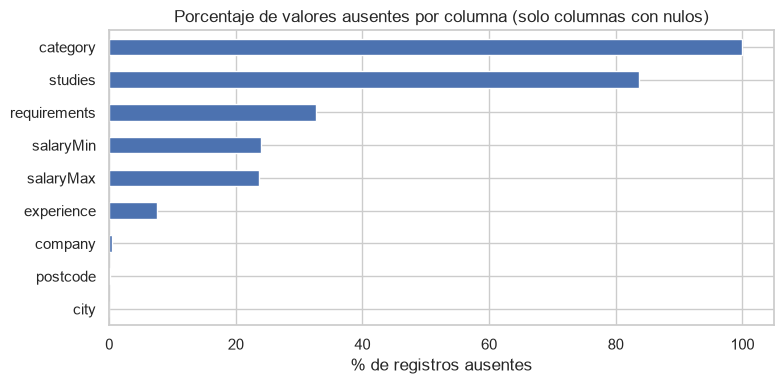

In [32]:
# Gráfico sencillo: % de nulos en columnas con al menos un valor ausente
nulos_pct_cols = (df_feina.isna().mean() * 100).round(2)
nulos_pct_cols = nulos_pct_cols[nulos_pct_cols > 0].sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 4))
nulos_pct_cols.plot(kind="barh", ax=ax)
ax.set_title("Porcentaje de valores ausentes por columna (solo columnas con nulos)")
ax.set_xlabel("% de registros ausentes")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Al analizar la calidad inicial observamos que casi todas las columnas se cargan como texto (`str`) y `category` aparece como object porque todos sus valores son nulos (4.890 ausentes, el 100.00 %), por lo que no aporta información en este lote; `studies` también tiene una alta ausencia (83.64 %), seguida de `requirements` (32.74 %), `salaryMin` (23.99 %), `salaryMax` (23.72 %) y `experience` (7.48 %), mientras que `company`, `postcode` y `city` tienen porcentajes mínimos y once campos están completos. Asimismo, no hay filas duplicadas exactas ni id repetidos (4.890 identificadores únicos), y en la limpieza convendrá convertir `salaryMin` y `salaryMax` a tipo numérico y date a fecha.

## 6. Exploración de variables numéricas y categóricas.

Convertimos temporalmente salaryMin y salaryMax a numérico para ver su distribución y detectar posibles valores atípicos o rangos inconsistentes, y revisamos las frecuencias de las principales variables categóricas.

In [33]:
# Resúmenes numéricos (salarios) y frecuencias de categorías principales
sal_min = pd.to_numeric(df_feina["salaryMin"], errors="coerce")
sal_max = pd.to_numeric(df_feina["salaryMax"], errors="coerce")

print("=== RESUMEN NUMÉRICO DE SALARIOS (EN MUESTRA CRUDA) ===")
df_salarios = pd.DataFrame({
    "salaryMin": sal_min,
    "salaryMax": sal_max
})
display(df_salarios.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]))

print("\nCasos donde salaryMin > salaryMax:", int((sal_min > sal_max).sum()))
print("Casos con salario <= 0:", int(((sal_min <= 0) | (sal_max <= 0)).sum()))

columnas_cat = ["status", "origin", "region", "workingHours", "disability", "contract"]
for col in columnas_cat:
    print(f"\n=== TOP F VALUES DE '{col}' (incluyendo nulos) ===")
    display(df_feina[col].value_counts(dropna=False).head(10))

=== RESUMEN NUMÉRICO DE SALARIOS (EN MUESTRA CRUDA) ===


,salaryMin,salaryMax
count,3717.000000,3730.000000
mean,1503.632230,1688.489008
std,707.000717,841.808241
min,80.000000,80.000000
5%,277.000000,324.500000
25%,1200.000000,1221.000000
50%,1500.000000,1653.000000
75%,1925.000000,2150.000000
95%,2500.000000,3000.000000
max,6000.000000,9999.000000



Casos donde salaryMin > salaryMax: 0
Casos con salario <= 0: 0

=== TOP F VALUES DE 'status' (incluyendo nulos) ===


status
PUBLISHED    4890
Name: count, dtype: int64


=== TOP F VALUES DE 'origin' (incluyendo nulos) ===


origin
FA       4189
SICAS     701
Name: count, dtype: int64

... (4 outputs left out)


=== TOP F VALUES DE 'disability' (incluyendo nulos) ===


disability
No    4575
Si     315
Name: count, dtype: int64


=== TOP F VALUES DE 'contract' (incluyendo nulos) ===


contract
Contracte laboral indefinit              3280
Contracte laboral temporal (1 mesos)      402
Contracte laboral temporal (6 mesos)      260
Contracte laboral temporal (3 mesos)      221
Contracte laboral temporal (12 mesos)     190
Contracte laboral temporal (2 mesos)      165
Contracte laboral temporal (9 mesos)       73
Contracte laboral temporal (4 mesos)       70
Contracte mercantil (només ofertes)        62
Contracte laboral temporal (8 mesos)       51
Name: count, dtype: int64

En salarios no hay rangos invertidos (`salaryMin` > `salaryMax` es 0) ni valores menores o iguales a 0, pero sí cierta dispersión: el mínimo es 80 € (probablemente asociado a jornadas parciales o reducidas) y los máximos llegan a 6.000 € en `salaryMin` y 9.999 € en `salaryMax`, con medianas (50%) de 1.500 € y 1.653 €. En las variables categóricas, las 4.890 ofertas están en estado `PUBLISHED`, se reparten entre `FA` (4.189) y `SICAS` (701), se concentran mayoritariamente en `BARCELONA` (3.163), `GIRONA` (656), `TARRAGONA` (553) y `LLEIDA` (501) con muy pocos casos fuera de Cataluña, predomina la `Jornada completa` (2.975) sobre la intensiva y las distintas jornadas parciales, `disability` marca No en 4.575 casos frente a Si en 315, y en `contract` destaca `Contracte laboral indefinit` (3.280) seguido de contratos temporales de distinta duración.

## 7. Verificación estructural (origin frente a rama XML) y observaciones de texto.

Comprobamos la correspondencia entre cada bloque de `<ofertes>` (`feinaactiva` y `sicas`) y la columna `origin`, además de revisar los valores más frecuentes de `company` y la presencia de saltos de línea en `content` para tener criterios sólidos de cara a la limpieza.

In [ ]:
# Chequeo de relación rama XML <-> origin y observaciones de texto
rama_por_ad = []
for rama in root:
    for ad in rama.findall(".//ad"):
        rama_por_ad.append(rama.tag)

df_check = pd.DataFrame({
    "rama_xml": rama_por_ad,
    "origin": df_feina["origin"]
})
print("=== CRUCE RAMA XML vs ORIGIN ===")
display(pd.crosstab(df_check["rama_xml"], df_check["origin"], margins=True))

print("\n=== TOP 8 VALORES EN COMPANY (INCLUYENDO NULOS) ===")
display(df_feina["company"].value_counts(dropna=False).head(8))

saltos_content = df_feina["content"].fillna("").str.contains(r"[\r\n]", regex=True).sum()
print(f"\nOfertas con saltos de línea en 'content': {saltos_content} de {len(df_feina)}")

=== CRUCE RAMA XML vs ORIGIN ===


origin,FA,SICAS,All
rama_xml,,,
feinaactiva,4189,0,4189
sicas,0,701,701
All,4189,701,4890



=== TOP 8 VALORES EN COMPANY (INCLUYENDO NULOS) ===


company
Oficina de Treball del SOC        665
Estudi 6 Gestió Socioeducativa    143
GENERALITAT DE CATALUNYA           98
EULEN.SA                           71
Nascor Formación SLU               54
TOYS CENTRE SL                     50
OFICINA DE TREBALL DEL SOC         43
SERNET SERVEIS                     37
Name: count, dtype: int64


Ofertas con saltos de línea en 'content': 3242 de 4890


El cruce confirma una correspondencia exacta entre la estructura del XML y el campo `origin`: todos los registros de `feinaactiva` (4.189) corresponden a `FA` y todos los de `sicas` (701) a `SICAS`, sumando las 4.890 ofertas sin cruces cruzados. En `company` destacan entidades recurrentes como `Oficina de Treball del SOC` (665 casos, a los que se suman 43 bajo OFICINA DE TREBALL DEL SOC por diferencia de mayúsculas/minúsculas), `Estudi 6 Gestió Socioeducativa` (143) y `GENERALITAT DE CATALUNYA` (98), mientras que 3.242 de las 4.890 ofertas presentan saltos de línea en `content` que convendrá normalizar en la capa Silver para unificar textos y nombres de entidad.

## 8. Revisión de ubicación y extremos salariales

Comprobamos la longitud de los códigos postales (`postcode`), los municipios más frecuentes (`city`) y algunos casos concretos en los extremos de `salaryMin` y `salaryMax` para distinguir entre valores poco habituales plausibles y posibles anomalías.

In [36]:
# Códigos postales distintos de 5 caracteres y top municipios
cp_limpios = df_feina["postcode"].dropna().astype(str).str.strip()
cp_raros = cp_limpios[cp_limpios.str.len() != 5]
print("Códigos postales no nulos con longitud != 5:", len(cp_raros))
if len(cp_raros) > 0:
    print("Valores:", cp_raros.unique()[:10])

print("\nTop 10 municipios (city):")
display(df_feina["city"].value_counts(dropna=False).head(10))

# Ejemplos concretos de salarios bajos y altos
df_ext = df_feina.copy()
df_ext["s_min"] = pd.to_numeric(df_ext["salaryMin"], errors="coerce")
df_ext["s_max"] = pd.to_numeric(df_ext["salaryMax"], errors="coerce")

print("\nEjemplos con salaryMin < 500:")
display(df_ext[df_ext["s_min"] < 500][["id", "title", "workingHours", "salaryMin", "salaryMax"]].head(8))

print("\nEjemplos con salaryMax >= 5000:")
display(df_ext[df_ext["s_max"] >= 5000][["id", "title", "workingHours", "salaryMin", "salaryMax"]].head(8))

Códigos postales no nulos con longitud != 5: 0

Top 10 municipios (city):


city
BARCELONA                      953
LLEIDA                         190
TARRAGONA                      135
SABADELL                       127
TERRASSA                       121
GIRONA                         120
REUS                            96
BADALONA                        88
HOSPITALET DE LLOBREGAT, L'     86
GRANOLLERS                      81
Name: count, dtype: int64


Ejemplos con salaryMin < 500:


,id,title,workingHours,salaryMin,salaryMax
67,FA92323099,LIMPIADOR@ DE HOGAR EN TERRASSA,Jornada parcial matí (2 hores - jornada setmanal),100,105
99,FA92323356,MONITOR/A DE MENJADOR ESCOLAR,Jornada parcial (2 hores - jornada diaria),400,430
125,FA92323127,MONITOR/A DE TRANSPORTE ESCOLAR - VILAFRANCA D...,Jornada parcial (12 hores - jornada setmanal),400,500
131,FA92323195,MOZO/ MOZA ALMACÉN (2H TURNO TARDE),Jornada parcial (2 hores - jornada diaria),356,357
135,FA92323146,PERSONAL DINAMITZACIÓ DE PASSEJADES PEL RIU BE...,Jornada parcial (22 hores - jornada mensual),313,314
194,FA92323551,MONITORS/MONITORES ESPAI MIGDIA PER GRUP SABADELL,Jornada parcial (10 hores - jornada setmanal),412,412
197,FA92323546,"AGENTES SOPORTE ESCOLAR - IDIOMA ÁRABE, URDÚ O...",Jornada parcial (12 hores - jornada setmanal),435,435
216,FA92323281,LIMPIADOR/A,Jornada parcial matí (7 hores - jornada setmanal),266,266



Ejemplos con salaryMax >= 5000:


,id,title,workingHours,salaryMin,salaryMax
149,FA92323583,EJECUTIVO/A DE CUENTAS,Jornada completa,2000,6000
1287,FA92325067,COMERCIALES B2B FREELANCE / SALES CLOSER – SOF...,Jornada completa,1221,5000
1600,FA92325747,AGENT COMERCIAL,Jornada parcial matí (6 hores - jornada setmanal),1300,8000
2165,FA92326646,COMERCIALES INMOBILIARIOS/AS BARCELONA CIUDAD ...,Jornada parcial (30 hores - jornada setmanal),1500,7000
2226,FA92326733,CHÓFERES DE PORTACOCHES PARA TRABAJAR EN ESPAÑ...,Jornada completa,2000,6000
2229,FA92326718,AGENT COMERCIAL B2B DE CAMP,Jornada parcial matí (6 hores - jornada diaria),1525,9999
2385,FA92326950,JEFES/AS DE PRODUCCIÓN - OBRA CIVIL (H/M),Jornada completa,3000,6000
2417,FA92326995,DIRECTOR/A D'OPERACIONS I CADENA DE SUBMINISTR...,Jornada completa,6000,6000


Un gráfico de barras del top de regiones/provincias ayuda a visualizar la concentración de ofertas en el territorio y el peso minoritario de ubicaciones fuera de las provincias habituales.

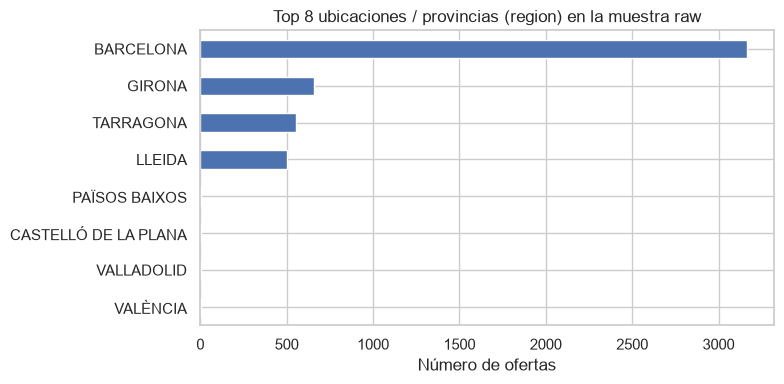

In [37]:
# Gráfico sencillo: Top 8 regiones/provincias (region)
top_regiones = df_feina["region"].fillna("Sin especificar").value_counts().head(8)

fig, ax = plt.subplots(figsize=(8, 4))
top_regiones.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Top 8 ubicaciones / provincias (region) en la muestra raw")
ax.set_xlabel("Número de ofertas")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Todos los códigos postales no nulos tienen una longitud exacta de 5 caracteres, y en `city` destacan `BARCELONA` (947), `LLEIDA` (191), `TARRAGONA` (135), `SABADELL` (127) y `TERRASSA` (121), tal como refleja el gráfico en el dominio claro de las provincias catalanas frente a unos pocos casos fuera del territorio. En los extremos salariales, los valores bajos (`salaryMin < 500`) se asocian a jornadas parciales o de pocas horas, mientras que los valores altos (`salaryMax >= 5000`, con picos de hasta 9.999) aparecen en perfiles directivos/técnicos y sobre todo comerciales, donde pueden intervenir comisiones o cifras orientativas que conviene tratar con prudencia en la limpieza.

## 9. Exploración de requisitos, estudios, experiencia y discapacidad

Revisamos qué valores y patrones aparecen en `requirements`, `studies`, `experience` y `disability` (teniendo en cuenta el alto porcentaje de ausencias en studies y requirements detectado al inicio) para valorar su utilidad en la capa Silver.

In [38]:
print("Distribución de disability:")
display(df_feina["disability"].value_counts(dropna=False))

print("\nTop 8 valores en studies (no nulos):")
display(df_feina["studies"].dropna().value_counts().head(8))

print("\nTop 8 valores en requirements (no nulos):")
display(df_feina["requirements"].dropna().value_counts().head(8))

print("\nEjemplos de experience (no nulos):")
display(df_feina["experience"].dropna().head(5))

Distribución de disability:


disability
No    4575
Si     315
Name: count, dtype: int64


Top 8 valores en studies (no nulos):


studies
títol de grau - educació social                       23
GRAU INFERMERIA                                       15
títol fp de grau mig - electricitat i electrònica     12
títol fp de grau mig - administració                  10
Educació Social                                        9
títol de grau - psicologia                             7
diplomatura o enginyeria tècnica - educació social     7
Pedagogia, Psicopedagogia. (imprescindible).           7
Name: count, dtype: int64


Top 8 valores en requirements (no nulos):


requirements
català (parlat Superior, escrit Superior), espanyol (parlat Superior, escrit Superior)    314
català (parlat Superior, escrit Superior)                                                 290
Permisos de conduir: b                                                                    264
Disponibilitat de vehicle                                                                 154
Disponibilitat de vehicle, Permisos de conduir: b                                         111
espanyol (parlat Superior, escrit Superior), català (parlat Superior, escrit Superior)    104
català (parlat Mitjà, escrit Mitjà)                                                        94
espanyol (parlat Superior, escrit Superior)                                                85
Name: count, dtype: int64


Ejemplos de experience (no nulos):


0    Experiència 0 anys.. Competències / coneixemen...
1    Experiència 1 mesos. Experiència prèvia en prà...
2    Experiència 1 mesos. No es necesaria experienc...
3    Experiència 12 mesos. Experiència en gestoria,...
4    Experiència 1 anys. Haver treballat, anteriorm...
Name: experience, dtype: str

En `disability` se mantiene la misma distribución (No: 4.575, Si: 315), mientras que en `studies` los valores no nulos presentan formatos variados y mezcla de mayúsculas/minúsculas o formulaciones equivalentes (como `títol de grau - educació social`, `GRAU INFERMERIA` o `Educació Social`), lo que exige normalizar o mantener con cautela al tener un alto porcentaje de ausencias. Por su parte, `requirements` concentra principalmente niveles de `català` y `espanyol` (a veces en distinto orden) junto con carnet de conducir (`b`) y disponibilidad de vehículo, y `experience` combina indicaciones de tiempo con texto libre y competencias, por lo que convendrá tratarla con cuidado en la capa Silver.

## 10. Control de fechas y gráficos básicos del EDA.

Revisamos el formato y rango de la columna `date` para comprobar si hay fechas inválidas o fuera de lo esperado, y generamos dos gráficos sencillos (distribución de salarios y top categorías/provincias) para apoyar el diagnóstico visual.

Fechas que no cumplen formato dd/mm/yyyy: 0
Fecha mínima: 2026-08-21 00:00:00 | Fecha máxima: 2026-11-19 00:00:00


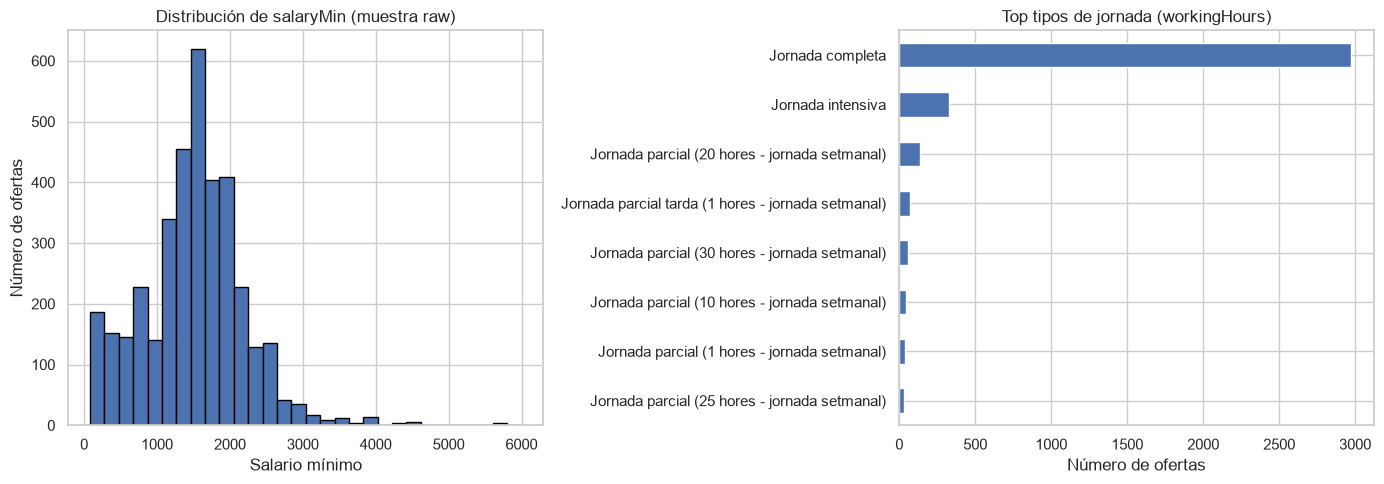

In [39]:
# Control de fechas y gráficos exploratorios sencillos
fechas_parseadas = pd.to_datetime(df_feina["date"], format="%d/%m/%Y", errors="coerce")
print("Fechas que no cumplen formato dd/mm/yyyy:", int(fechas_parseadas.isna().sum()))
print("Fecha mínima:", fechas_parseadas.min(), "| Fecha máxima:", fechas_parseadas.max())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Distribución de salaryMin (valores válidos)
sal_min_validos = sal_min.dropna()
axes[0].hist(sal_min_validos, bins=30, edgecolor="black")
axes[0].set_title("Distribución de salaryMin (muestra raw)")
axes[0].set_xlabel("Salario mínimo")
axes[0].set_ylabel("Número de ofertas")

# Gráfico 2: Top 8 jornadas laborales (workingHours)
top_jornadas = df_feina["workingHours"].fillna("Sin especificar").value_counts().head(8)
top_jornadas.sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Top tipos de jornada (workingHours)")
axes[1].set_xlabel("Número de ofertas")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

Todas las fechas cumplen el formato `dd/mm/yyyy` (0 inválidas) y se sitúan entre `2026-08-21` y `2026-11-19`, sin anomalías temporales. Visualmente, el histograma de `salaryMin` refleja la mayor densidad de ofertas en el entorno de `1.500`–`2.000 €` con una cola superior más dispersa y casos bajos ligados a jornadas parciales, y el gráfico de barras de `workingHours` evidencia la amplia mayoría de `Jornada completa` frente a la jornada intensiva y las variantes de jornada parcial.